This chapter closes the prerequisites and opens the door to the drug-discovery part of the course. A drug is just a molecule that binds something in the body and changes what it does. Everything else, potency, selectivity, dose, side effects, is about *which* molecule binds *what*, *how tightly*, and what the body does to the molecule in between. These are the quantities that cheminformatics, docking and QSAR (Part 3) try to predict.

:::eli5
A drug is a small molecule shaped to fit a particular pocket on a particular protein, like a key cut for one lock. When it fits, it jams the lock (blocks the protein) or turns it (switches the protein on). A good drug fits its target lock tightly (**potency**), ignores the thousands of other locks in the body (**selectivity**), survives long enough to do its job but not forever (**pharmacokinetics**), and can actually reach the lock, which for a pill means surviving the gut and getting into the blood. Most molecules fail at one of these, which is why making a new medicine is so hard.
:::

## What a drug targets

Most drugs are small molecules that bind a protein and change its activity. The main target classes:

| Target | What the drug does | Examples |
|---|---|---|
| **Enzymes** | usually block the active site (chapter P5) | statins, kinase inhibitors, aspirin |
| **G-protein-coupled receptors** | activate (agonist) or block (antagonist) | beta-blockers, antihistamines, opioids |
| **Ion channels** | block or modulate the pore | local anaesthetics, many heart drugs |
| **Nuclear receptors** | change gene transcription | steroids, tamoxifen |
| **Transporters** | block a pump | SSRI antidepressants, some diuretics |

Beyond small molecules, **biologics** (antibodies, chapter P10; engineered proteins) target things outside cells, and newer approaches (antisense oligonucleotides, siRNA, mRNA, PROTACs that tag a protein for destruction, chapter P5) are expanding what can be drugged.

## Binding, affinity and occupancy

A drug works by binding its target, and binding is the equilibrium from chapter P2. The key number is the **dissociation constant** $K_d$: the concentration of drug at which half the target is occupied. Smaller $K_d$ means tighter binding.

:::math
At drug concentration $[L]$, the fraction of target bound is
$$\theta = \frac{[L]}{[L] + K_d}.$$
For an enzyme inhibitor the equivalent constant is often called $K_i$, and the measured concentration producing half-maximal effect in an assay is the $\text{IC}_{50}$ (for inhibition) or $\text{EC}_{50}$ (for activation). All are concentrations: the smaller, the more potent.
:::

Drug concentrations span an enormous range, so they are always discussed on a log scale, usually as **pIC50** $= -\log_{10}(\text{IC}_{50}\text{ in M})$. A 1 nM drug has pIC50 = 9; a 1 µM drug pIC50 = 6. Each unit of pIC50 is a 10-fold change in potency, and corresponds to about 5.9 kJ/mol of binding energy (chapter P2). The first tab of the playground shows how the dose–response curve and the therapeutic window depend on these numbers.

::playground animations/pharm_lab.html 620

## Potency is not enough: selectivity and the therapeutic window

A drug that blocks its target at 1 nM is useless if it also blocks ten other proteins at 2 nM. **Selectivity** is the gap between the concentration that hits the target and the concentration that causes harm. At the whole-body level this is the **therapeutic index**: the ratio between the toxic dose and the effective dose.

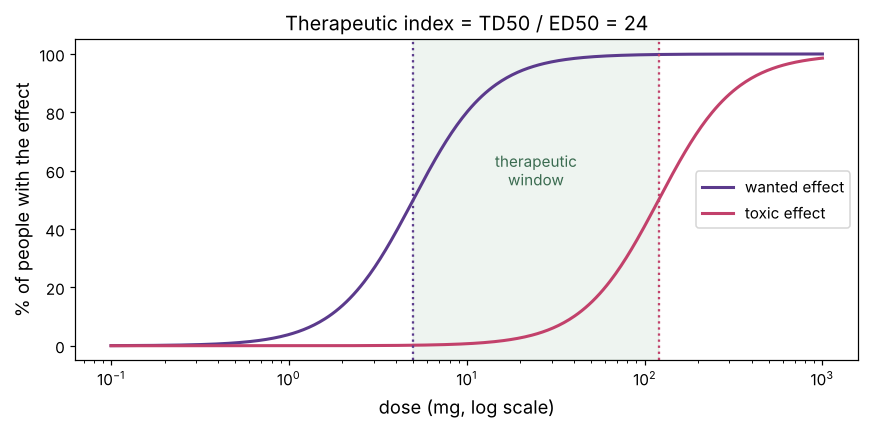

therapeutic index = 24


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

dose = np.logspace(-1, 3, 400)                       # mg, log scale
def response(d, ed50, n=2):
    return 100 * d ** n / (ed50 ** n + d ** n)
effect = response(dose, 5)                             # wanted effect, ED50 = 5 mg
toxic = response(dose, 120)                            # harmful effect, TD50 = 120 mg
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(dose, effect, color="#5b3a8c", lw=2, label="wanted effect")
ax.semilogx(dose, toxic, color="#c2416b", lw=2, label="toxic effect")
ed50, td50 = 5, 120
ax.axvline(ed50, color="#5b3a8c", ls=":"); ax.axvline(td50, color="#c2416b", ls=":")
ax.axvspan(ed50, td50, color="#8fb7a0", alpha=0.15)
ax.text(np.sqrt(ed50 * td50), 55, "therapeutic\nwindow", ha="center", fontsize=10, color="#3a6b50")
ax.set_xlabel("dose (mg, log scale)"); ax.set_ylabel("% of people with the effect"); ax.legend(loc="center right")
ax.set_title(f"Therapeutic index = TD50 / ED50 = {td50 / ed50:.0f}")
save_fig("therapeutic_window"); plt.show()
R["ti"] = f"{td50 / ed50:.0f}"
print(f"therapeutic index = {td50 / ed50:.0f}")

![Figure P13-1. Dose–response for the wanted effect (left) and toxicity (right). The gap between them is the therapeutic window. A large therapeutic index means the dose can be set comfortably between too little and too much.](images/therapeutic_window.png)

Here the toxic dose is 24 times the effective dose. Penicillin has a huge therapeutic index (hard to overdose); warfarin (a blood thinner) and most chemotherapies have a narrow one, so their blood levels are monitored and doses individualised. Narrow windows are a major reason drugs fail or are withdrawn, and predicting toxicity early is a central goal of computational drug discovery.

## What the body does to the drug: ADME

Binding the target is necessary but not sufficient. The drug must also get to the target and stay around the right length of time. That is **pharmacokinetics**, summarised as **ADME**:

- **Absorption**: for a pill, getting from the gut into the blood. The fraction that makes it is the **bioavailability** $F$.
- **Distribution**: spreading through the body's water, tissues and fat.
- **Metabolism**: chemical modification, mostly in the liver by **cytochrome P450** enzymes, usually to inactivate the drug and make it easier to excrete. A big source of drug–drug interactions.
- **Excretion**: removal, mostly by the kidneys into urine, or by the liver into bile.

A simple and surprisingly useful model treats the body as one well-mixed compartment. The drug is absorbed from the gut at rate $k_a$ and eliminated at rate $k_e$:

:::math
$$\frac{dA_\text{gut}}{dt} = -k_a A_\text{gut}, \qquad \frac{dC}{dt} = \frac{k_a A_\text{gut}}{V} - k_e C,$$

where $C$ is blood concentration and $V$ the **volume of distribution**. The elimination half-life is $t_{1/2} = \ln 2 / k_e$. With repeated doses every $\tau$ hours, the drug accumulates to an average steady state $C_\text{ss} = \dfrac{F \cdot \text{dose}}{V k_e \tau}$, reached after about 4–5 half-lives.
:::

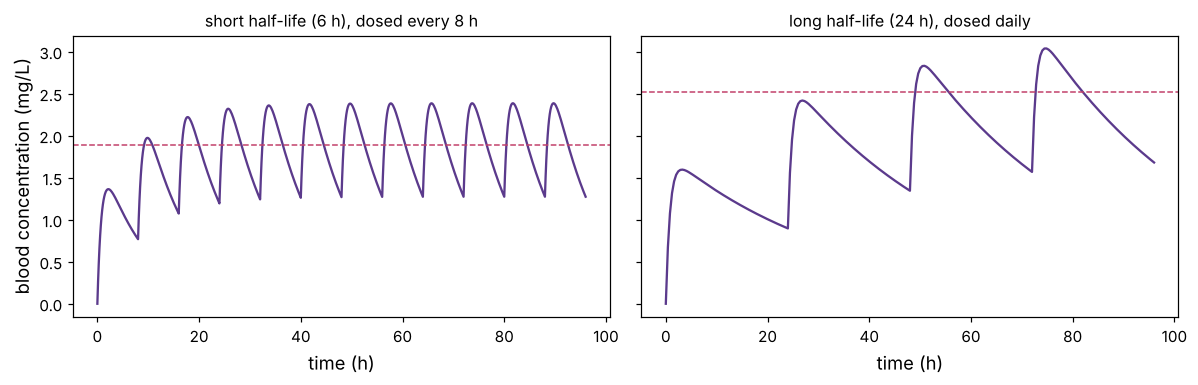

time to steady state ≈ 4-5 half-lives


In [2]:
from scipy.integrate import solve_ivp
def pk(t, y, ka, ke, V, F, dose, tau):
    gut, C = y
    return [-ka * gut, ka * gut / V - ke * C]

def dosing(ka, ke, V, F, dose, tau, T=96):
    times, conc = [], []
    gut = C = 0.0
    t = 0.0
    while t < T:
        gut += F * dose                                     # take a dose
        sol = solve_ivp(pk, (t, t + tau), [gut, C], args=(ka, ke, V, F, dose, tau), max_step=0.1, dense_output=True)
        tt = np.linspace(t, t + tau, 60)
        times += list(tt); conc += list(sol.sol(tt)[1])
        gut, C = sol.y[0, -1], sol.y[1, -1]
        t += tau
    return np.array(times), np.array(conc)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (half, tau, title) in zip(axs, [(6, 8, "short half-life (6 h), dosed every 8 h"), (24, 24, "long half-life (24 h), dosed daily")]):
    ke = np.log(2) / half
    t, c = dosing(ka=1.2, ke=ke, V=40, F=0.7, dose=100, tau=tau)
    css = 0.7 * 100 / (40 * ke * tau)
    ax.plot(t, c, color="#5b3a8c"); ax.axhline(css, color="#c2416b", ls="--", lw=1)
    ax.set_title(title, fontsize=10.5); ax.set_xlabel("time (h)")
axs[0].set_ylabel("blood concentration (mg/L)")
save_fig("pk_dosing"); plt.show()
ke = np.log(2) / 24
R["css_daily"] = f"{0.7 * 100 / (40 * ke * 24):.2f}"
print("time to steady state ≈ 4-5 half-lives")

![Figure P13-2. Blood levels under repeated dosing. A short half-life gives big swings between doses; a long half-life gives steady levels but takes days to build up (dashed line = average steady state).](images/pk_dosing.png)

The second tab of the playground lets you change dose, interval and half-life and watch the curve. The trade-off is general: short half-life means frequent dosing or big swings; long half-life means smooth levels but slow onset, which is why long-acting drugs often start with a **loading dose**.

## Can it even be a pill? Lipinski's rule of five

A molecule has to cross the oily gut lining (chapter P2) to be absorbed, yet dissolve in water to travel in blood. Christopher Lipinski looked at thousands of drugs in 1997 and found that oral drugs rarely violate more than one of four limits (all multiples of five, hence "rule of five"): molecular weight ≤ 500, no more than 5 hydrogen-bond donors, no more than 10 acceptors, and $\log P \le 5$ ($\log P$ measures oiliness, chapter P2). Let's check it on real data: every small-molecule drug ever approved, downloaded from the **ChEMBL** database.

3,147 approved small-molecule drugs with properties


oral drugs passing (≤1 violation): 90%
non-oral drugs passing: 87%


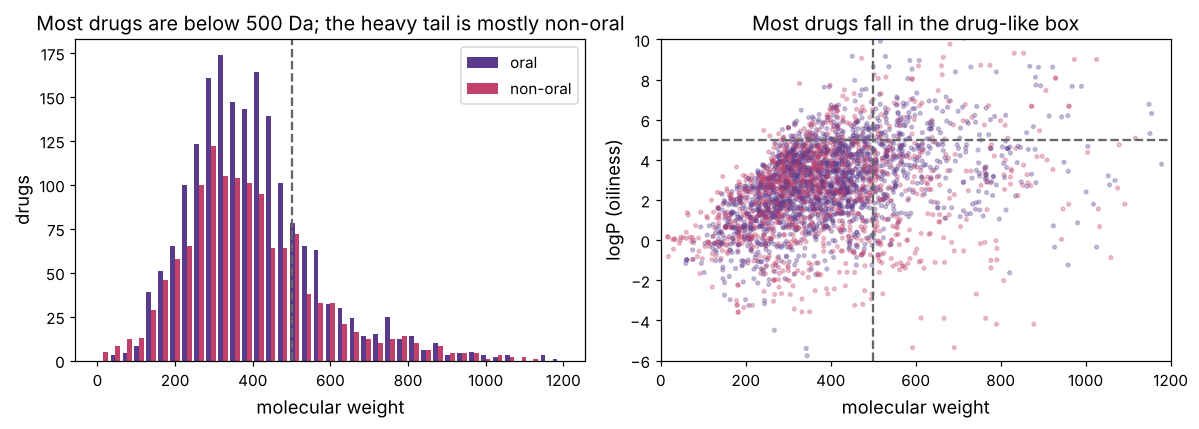

In [3]:
import pandas as pd
drugs = pd.read_csv("datasets/chembl_approved_small_molecules.csv")
drugs = drugs.dropna(subset=["mw", "alogp", "hbd", "hba"])
print(f"{len(drugs):,} approved small-molecule drugs with properties")

def violations(row):
    return int(row.mw > 500) + int(row.hbd > 5) + int(row.hba > 10) + int(row.alogp > 5)
drugs["viol"] = drugs.apply(violations, axis=1)
oral = drugs[drugs.oral == True]
print(f"oral drugs passing (≤1 violation): {(oral.viol <= 1).mean():.0%}")
print(f"non-oral drugs passing: {(drugs[drugs.oral == False].viol <= 1).mean():.0%}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist([oral.mw, drugs[drugs.oral == False].mw], bins=np.linspace(0, 1200, 40), label=["oral", "non-oral"], color=["#5b3a8c", "#c2416b"])
axs[0].axvline(500, color="0.4", ls="--"); axs[0].set_xlabel("molecular weight"); axs[0].set_ylabel("drugs"); axs[0].legend(); axs[0].set_title("Most drugs are below 500 Da; the heavy tail is mostly non-oral")
axs[1].scatter(drugs.mw, drugs.alogp, s=6, alpha=0.3, c=np.where(drugs.oral == True, "#5b3a8c", "#c2416b"))
axs[1].axvline(500, color="0.4", ls="--"); axs[1].axhline(5, color="0.4", ls="--")
axs[1].set_xlabel("molecular weight"); axs[1].set_ylabel("logP (oiliness)"); axs[1].set_xlim(0, 1200); axs[1].set_ylim(-6, 10)
axs[1].set_title("Most drugs fall in the drug-like box")
save_fig("lipinski"); plt.show()
R["oral_pass"] = f"{(oral.viol <= 1).mean():.0%}"; R["nonoral_pass"] = f"{(drugs[drugs.oral == False].viol <= 1).mean():.0%}"
R["mw_med"] = f"{oral.mw.median():.0f}"

![Figure P13-3. Left: both oral (purple) and injected (red) drugs cluster below 500 Da, but the heavy tail past 600 Da is mostly injected drugs that skip the gut. Right: molecular weight against oiliness; most drugs sit inside Lipinski's box (lower left of the dashed lines).](images/lipinski.png)

Of approved **oral** drugs, 90% satisfy the rule of five, with a median weight of just 379 Da. Injected drugs pass slightly less often (87%), but the real difference is in the tail: because they skip the gut, they include the genuinely large molecules (antibiotics like vancomycin, many cancer drugs) that no pill could absorb, as the weight histogram shows. The rule is a guideline, not a law: there are famous exceptions, and whole classes of modern drugs (the "beyond rule of five" space) deliberately break it. But it captures why most of the screening libraries in Part 3 are built from small, not-too-greasy molecules.

### Ligand efficiency: potency per atom

A big molecule can always bind more tightly by adding more contacts, but big molecules make bad drugs. Medicinal chemists therefore track **ligand efficiency**: binding energy per heavy (non-hydrogen) atom. It keeps molecules small as they are optimised.

:::math
$$\text{LE} = \frac{1.37 \times \text{pIC}_{50}}{\text{number of heavy atoms}} \quad \text{(kcal/mol per atom)},$$
using $\Delta G \approx -1.37\,\text{pIC}_{50}$ kcal/mol at room temperature. A useful lead has LE around 0.3 or more.
:::

In [4]:
heavy_atoms = drugs.mw / 13.3                            # rough: average heavy atom ~13 Da in organic molecules
for name, pic50, ha in [("a fragment hit", 4.5, 12), ("a lead", 6.5, 24), ("a drug", 9.0, 38)]:
    le = 1.37 * pic50 / ha
    print(f"{name:16s} pIC50 {pic50}  heavy atoms {ha:2d}  ligand efficiency {le:.2f}")
R["le_lead"] = f"{1.37 * 6.5 / 24:.2f}"

a fragment hit   pIC50 4.5  heavy atoms 12  ligand efficiency 0.51
a lead           pIC50 6.5  heavy atoms 24  ligand efficiency 0.37
a drug           pIC50 9.0  heavy atoms 38  ligand efficiency 0.32


A weak **fragment** that binds a small pocket can have excellent ligand efficiency, and growing it carefully into a potent drug while keeping LE high is the strategy behind **fragment-based drug discovery** (chapter 15). Keeping this number in view stops a project from reaching high potency by bolting on greasy, drug-killing bulk.

## From molecule to medicine

Turning a promising molecule into an approved drug takes 10–15 years and billions of dollars, and most candidates fail. The stages:

| Stage | What happens | Attrition |
|---|---|---|
| **Target identification** | find a protein whose modulation should help (genetics, chapter P8; CRISPR screens, chapter P11) | |
| **Hit finding** | screen large libraries, or fragments, for anything that binds (chapter 13) | |
| **Lead optimisation** | medicinal chemistry: improve potency, selectivity, ADME, safety (chapters 13–15) | |
| **Preclinical** | test in cells and animals for efficacy and toxicity | |
| **Phase I** | safety and dosing in a few healthy volunteers | about 90% advance |
| **Phase II** | does it work, in a few hundred patients | most failures here |
| **Phase III** | large randomised trial against the current standard | expensive |
| **Approval and Phase IV** | regulators review; monitoring continues after launch | |

Only about 1 in 10 drugs that enter clinical trials is approved, and far fewer of the molecules made at the start. Failures come from lack of efficacy and from unexpected toxicity, often appearing late and expensively. That economic reality is why computational methods, which aim to kill bad molecules early and cheaply and to find better starting points, are so valuable, and it is what the rest of this course builds towards.

:::idea
Every quantity in this chapter is something a model tries to predict from a molecule's structure. Can we predict binding affinity (docking, chapter 15; QSAR, chapter 14)? Solubility, absorption and metabolism (ADME models, chapter 16)? Toxicity? Whether a target is even druggable (chapter 11)? Part 3 of this course is, in effect, the computational version of this chapter.
:::

## The drug-discovery part of this course

You now have the whole biological foundation. From here the course turns computational, and each field builds directly on these prerequisites:

- **Bioinformatics** (Part 1): read and compare the sequences from chapters P3–P4.
- **Omics and machine learning** (Part 2): measure gene regulation (P6) across thousands of cells, and predict function with deep learning.
- **Structure and drug discovery** (Part 3): the proteins (P5), binding (P2) and pharmacology (this chapter) of finding new medicines.
- **Systems biology** (Part 4): the pathways (P9) and populations (P7, P8) as dynamical systems.
- **Cancer research** (Part 5): everything, applied to the disease of chapter P12.

## Summary

| Idea | One line |
|---|---|
| Target | mostly proteins: enzymes, receptors, channels, transporters |
| Affinity | Kd / Ki / IC50: concentration for half-effect; smaller = more potent |
| pIC50 | −log10(IC50); each unit is 10× potency and ~5.9 kJ/mol |
| Therapeutic index | toxic dose / effective dose; wide is safe, narrow needs monitoring |
| ADME | absorption, distribution, metabolism, excretion set the dosing |
| Half-life | sets dosing frequency; steady state after ~4–5 half-lives |
| Rule of five | oral drugs: MW ≤ 500, HBD ≤ 5, HBA ≤ 10, logP ≤ 5 |
| Ligand efficiency | binding energy per heavy atom; keeps drugs small |

:::check
1. Drug A has IC50 = 10 nM and drug B 1 µM for the same target. Which is more potent, and by how much? *(A, by 100-fold.)*
2. What is the therapeutic index, and why does a small one matter? *(Toxic dose / effective dose; a small one means little room between helping and harming, so levels must be monitored.)*
3. A drug has a 24-hour half-life. Roughly how long until it reaches steady state on daily dosing? *(About 4–5 days.)*
4. Why do injected drugs break Lipinski's rule more often than pills? *(They skip the gut, so they don't need to be absorbed orally.)*
5. Why do chemists track ligand efficiency rather than just potency? *(To reach potency without adding size and greasiness that ruin a molecule's drug-like properties.)*
:::

:::exercise
Using the ChEMBL table, compare drugs approved before 1990 with those approved from 2010 onward. (a) Has the median molecular weight changed? (b) What fraction of each group passes the rule of five? Modern targets are often "harder" (protein–protein interactions, kinases). Does the data hint at drugs drifting out of classic drug-like space?
:::

<details><summary>Solution</summary>

In [5]:
drugs["era"] = np.where(drugs.first_approval < 1990, "before 1990", np.where(drugs.first_approval >= 2010, "2010+", "1990-2009"))
for era in ["before 1990", "2010+"]:
    g = drugs[drugs.era == era]
    print(f"{era:12s} n={len(g):4d}  median MW {g.mw.median():5.0f}  median logP {g.alogp.median():.1f}  pass rule of five {np.mean(g.viol <= 1):.0%}")

before 1990  n=1314  median MW   339  median logP 2.4  pass rule of five 90%
2010+        n= 643  median MW   460  median logP 3.3  pass rule of five 80%


Drugs approved since 2010 tend to be noticeably heavier than those from before 1990, and a somewhat larger fraction violate the rule of five. As the easy targets were exhausted, the industry moved to harder ones that need bigger molecules, pushing into "beyond rule of five" space. The trend is real but modest: small, drug-like molecules still dominate, which is why the screening libraries and models in Part 3 still focus on them. (The exact numbers depend on how many older drugs ChEMBL records with approval dates, so treat them as indicative.)

</details>